In [1]:
from io import BytesIO

import pandas as pd
import requests
from IPython.display import display
from PIL import Image

In [2]:
df = pd.read_parquet(r"data/processed/joined_dataset.parquet")

In [3]:
df.head(1)

,query_id,query,product_id,product_title,image_url,esci_label
0,2,!qscreen fence without holes,B07D7TBSGH,FOTMISHU 6Pcs Greenhouse Hoops Rust-Free Grow ...,https://m.media-amazon.com/images/I/61CDCtvFO+...,I


In [4]:
def row_prettier(num: int) -> None:
    print(f"QUERY : {df.iloc[num]['query']}")
    print(f"PID : {df.iloc[num]['product_id']}")
    print(f"PIT : {df.iloc[num]['product_title']}")
    print(f"Image_URL : {df.iloc[num]['image_url']}")
    print(f"Label : {df.iloc[num]['esci_label']}")
    url = df.iloc[num]["image_url"]
    try:
        resp = requests.get(url, timeout=15)
        resp.raise_for_status()
        img = Image.open(BytesIO(resp.content)).convert("RGB")
        img.thumbnail((400, 400))  # keep notebook cells compact
        display(img)
    except Exception as e:
        print(f"[image error] {e}")

QUERY : #1 rated resveratrol supplement without tea leaves
PID : B000MYW2ZA
PIT : LifeExtension LIFE235 Extracto De Té Verde Mega Descafeinado 100 Cápsulas Vegetarianas
Image_URL : https://m.media-amazon.com/images/I/61WgjQ2VudL._AC_SY879_.jpg
Label : I


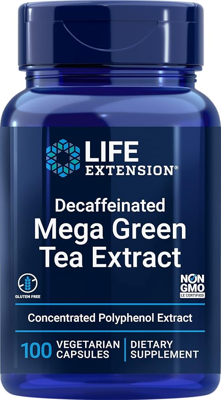

In [7]:
row_prettier(98)